# Exploratory data analysis - Beijing PM2.5

Project 19 (air quality forecasting via gradient boosting and LSTM models) - Team T024, Section A.

This is the first notebook. The written report for notebooks 01 and 02 is `reports/data_report.pdf`.
It reads the **original csv** (`data/raw/PRSA_data_2010.1.1-2014.12.31.csv`) and changes
nothing on disk. Its findings decide what the preprocessing notebook (`02_data_preprocessing.ipynb`) does and which
features the models (`03_phase1_models.ipynb`) use.

- **Part A, data quality.** Structure, missing values, gaps, value ranges and what odd columns mean. These are facts
  about how the data was recorded, so they are checked on all five years. Anything in Part A that describes how
  PM2.5 behaves or shapes a modelling choice (cost of filling, skew, typical wind speeds) uses 2010 to 2013 only.
  Output: the preprocessing decisions (A8).
- **Part B, exploration (2010 to 2013 only).** Patterns, cycles and drivers of PM2.5. 2014 is the test year; letting
  its patterns shape the model would be test-set leakage, so it stays hidden. Output: the modelling decisions (B11).

Column names are shortened when loading (for example `pm2.5` to `pm25`, `Iws` to `ws_cum`); values are untouched.
A few helper columns (hourly wind speed, relative humidity, rain flags) are computed inside this notebook for
analysis only. Preprocessing builds its own versions.

| Step | Question | Decides |
|---|---|---|
| A1 | Is the file complete and regular? | validation, no resampling |
| A2 | Which columns have missing values? | what needs handling |
| A3 | How are target gaps distributed, and what does filling cost? | imputation rule |
| A4 | Are the extreme values real? | keep or remove outliers |
| A5 | What do `Iws`, `Is`, `Ir` really contain? | decoding |
| A6 | Which wind directions exist? | encoding |
| A7 | Which columns are skewed? | log1p |
| A8 | Summary | preprocessing decisions |
| B1 to B10 | trend, pollution levels, cycles, memory, weather, next 6 h, episodes, Lunar New Year, redundancy, stationarity | features and model settings |
| B11 | Summary | modelling decisions |

## 0. Setup

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
from statsmodels.tsa.stattools import adfuller, pacf

from aqf import viz
from aqf.config import load_config
from aqf.data.audit import gaps
from aqf.data.load import NAMES
from aqf.features import LNY, rel_humidity

%config InlineBackend.figure_format = "retina"
pd.set_option("display.width", 120)
pd.set_option("display.precision", 2)
viz.use_style()

cfg = load_config("configs/data.yaml")
TEST = cfg["split"]["test_year"]

# Part A - Data quality (2010 to 2014)

## A1. Is the file complete and regular?

In [2]:
raw = pd.read_csv(cfg["paths"]["raw"])
print(raw.shape)
raw.head()

(43824, 13)


,No,year,month,day,hour,pm2.5,DEWP,TEMP,PRES,cbwd,Iws,Is,Ir
0,1,2010,1,1,0,NaN,-21,-11.0,1021.0,NW,1.79,0,0
1,2,2010,1,1,1,NaN,-21,-12.0,1020.0,NW,4.92,0,0
2,3,2010,1,1,2,NaN,-21,-11.0,1019.0,NW,6.71,0,0
3,4,2010,1,1,3,NaN,-21,-14.0,1019.0,NW,9.84,0,0
4,5,2010,1,1,4,NaN,-20,-12.0,1018.0,NW,12.97,0,0


In [3]:
raw.dtypes.to_frame("dtype").T

,No,year,month,day,hour,pm2.5,DEWP,TEMP,PRES,cbwd,Iws,Is,Ir
dtype,int64,int64,int64,int64,int64,float64,int64,float64,float64,object,float64,int64,int64


In [4]:
ts = pd.to_datetime(raw[["year", "month", "day", "hour"]]).rename("ts")
df = raw.rename(columns=NAMES).drop(columns=["No", "year", "month", "day", "hour"]).set_index(ts)
step = df.index.to_series().diff().dropna()
pd.Series({"rows": len(df), "first hour": df.index.min(), "last hour": df.index.max(),
           "duplicate hours": df.index.duplicated().sum(),
           "steps other than 1 h": (step != pd.Timedelta("1h")).sum()}).to_frame("value")

,value
rows,43824
first hour,2010-01-01 00:00:00
last hour,2014-12-31 23:00:00
duplicate hours,0
steps other than 1 h,0


**Takeaway.** One row per hour from 2010-01-01 00:00 to 2014-12-31 23:00, no duplicates and no skipped hours. The
grid is already regular, so preprocessing only has to verify it, not resample.

## A2. Which columns have missing values?

In [5]:
df.isna().sum().rename("missing").to_frame().T

,pm25,dewp,temp,pres,cbwd,ws_cum,snow_cum,rain_cum
missing,2067,0,0,0,0,0,0,0


**Takeaway.** Only the target `pm25` has missing values. Every weather column is complete, so nothing in the weather
needs filling.

## A3. Target gaps and the cost of filling them

In [6]:
pm = df["pm25"]
miss = pm.isna()
pd.Series({"missing hours": miss.sum(), "missing %": 100 * miss.mean()}).to_frame("pm25").T

,missing hours,missing %
pm25,2067.0,4.72


In [7]:
miss.groupby(df.index.year).sum().rename("missing hours").to_frame().T

ts,2010,2011,2012,2013,2014
missing hours,669,728,489,82,99


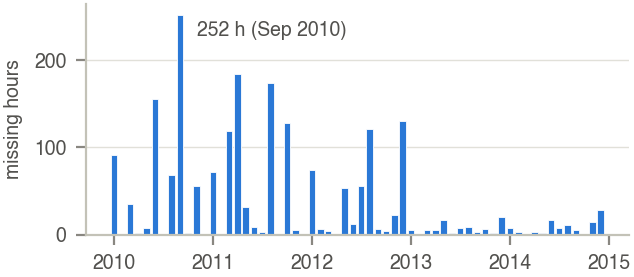

In [8]:
fig = viz.missing_by_month(df.assign(pm25_miss=miss.astype("int8")))

Each run of consecutive missing hours is one gap. Gap length decides what can be filled honestly.

In [9]:
g = gaps(miss)
bucket = pd.cut(g["size"], [0, 1, 3, 6, 24, np.inf], labels=["1 h", "2-3 h", "4-6 h", "7-24 h", "> 24 h"])
pd.DataFrame({"gaps": g.groupby(bucket, observed=False).size(),
              "missing hours": g.groupby(bucket, observed=False)["size"].sum()}).T

size,1 h,2-3 h,4-6 h,7-24 h,> 24 h
gaps,112,31,15,36,20
missing hours,112,64,74,476,1341


In [10]:
pd.Series({"gaps": len(g), "longest (h)": g["size"].max(),
           "longest starts": g.loc[g["size"].idxmax(), "start"]}).to_frame("value")

,value
gaps,214
longest (h),155
longest starts,2010-09-21 05:00:00


**What does filling cost?** Carrying the last value forward k hours is exactly a persistence guess k hours ahead.
Its average error on observed hours shows how wrong a filled value would be. Measured on 2010 to 2013 only, cut
before shifting so no 2014 value is involved.

In [11]:
dev = df.index.year < TEST
p = pm[dev]
pd.Series({f"{k} h": (p.shift(-k) - p).abs().mean() for k in [1, 2, 3, 4, 6, 12]},
          name="mean abs error of carrying forward (ug/m3)").to_frame().T

,1 h,2 h,3 h,4 h,6 h,12 h
mean abs error of carrying forward (ug/m3),13.12,20.85,27.04,32.31,40.81,56.35


**Takeaway.**
- 2,067 missing hours (4.72%) in 214 gaps. Most gaps are short: 112 last 1 hour and 143 last at most 3 hours. A few
  are long: 20 gaps exceed 24 hours, the longest is 155 hours from 2010-09-21.
- Missingness is not spread evenly: it is concentrated in 2010 to 2012 and much lower in 2013 and 2014.
- A carried-forward value is off by about 13 after 1 hour, 27 after 3 hours and 41 after 6 hours. Up to 3 hours
  the fill is close to the truth; beyond that it starts inventing data.
- Interpolation is not an option: it uses the value after the gap, which a forecaster would not have yet.

## A4. Are the extreme values real?

In [12]:
df.drop(columns="cbwd").agg(["min", "max"]).T

,min,max
pm25,0.00,994.0
dewp,-40.00,28.0
temp,-19.00,42.0
pres,991.00,1046.0
ws_cum,0.45,585.6
snow_cum,0.00,27.0
rain_cum,0.00,36.0


In [13]:
pd.concat([df.loc[t - pd.Timedelta("2h"): t + pd.Timedelta("2h"), ["pm25", "cbwd"]]
           for t in pm.nlargest(3).index[[0, 1]]])

,pm25,cbwd
ts,,
2012-01-22 23:00:00,161.0,cv
2012-01-23 00:00:00,225.0,NW
2012-01-23 01:00:00,994.0,NW
2012-01-23 02:00:00,972.0,NW
2012-01-23 03:00:00,430.0,NW
2010-02-13 23:00:00,267.0,cv
2010-02-14 00:00:00,351.0,NE
2010-02-14 01:00:00,980.0,cv
2010-02-14 02:00:00,NaN,NW


In [14]:
df.loc[pm.eq(0), ["pm25"]]

,pm25
ts,
2012-09-28 10:00:00,0.0
2012-09-28 15:00:00,0.0


**Takeaway.** Every range is physically plausible (for example dew point -40 to 28 C, pressure 991 to 1046 hPa).
The two highest PM2.5 values (994 and 980) fall in the first hours of Lunar New Year 2012 and 2010, and the
neighbouring hours rise and fall with them, so they are real fireworks pollution, not sensor errors. Only two hours
are exactly 0. No value is impossible, so nothing is clipped or removed.

## A5. What do `Iws`, `Is` and `Ir` really contain?

`Iws` is called "cumulated wind speed". If it were a running total per wind direction, it would only fall when the
direction changes.

In [15]:
new_run = df["cbwd"].ne(df["cbwd"].shift())
d = df["ws_cum"].diff()
pd.Series({"hours where Iws falls": (d < 0).sum(),
           "of those, at a direction change": ((d < 0) & new_run).sum(),
           "hours inside a run where Iws does not rise": ((d <= 0) & ~new_run).sum()}).to_frame("hours")

,hours
hours where Iws falls,8283
"of those, at a direction change",8283
hours inside a run where Iws does not rise,0


It falls only when the direction changes and always rises inside a run, so it is a running total that restarts
with each new direction. The hourly speed is the difference inside a run, and the raw value on the first hour of a
run. It is computed here for analysis; preprocessing step 2 does the same for the model.

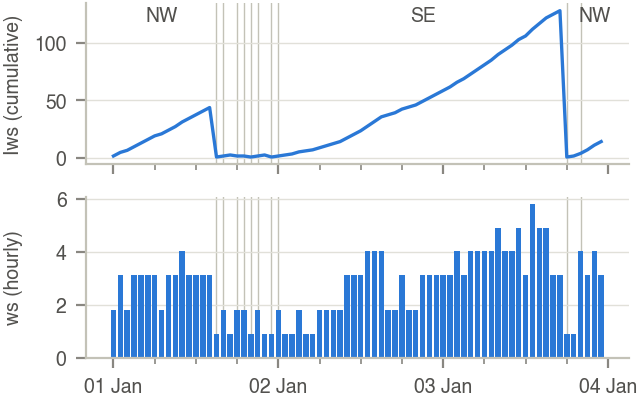

In [16]:
ws = df["ws_cum"].where(new_run, d)
fig = viz.wind_decode(df.assign(ws=ws))

`Is` and `Ir` are described as "cumulated hours of snow / rain". If they count consecutive hours, each positive value
should be the previous value plus 1.

In [17]:
rows = {}
for c in ["snow_cum", "rain_cum"]:
    s = df[c]
    rows[c] = {"hours > 0 (%)": 100 * (s > 0).mean(), "max": s.max(),
               "positive hours": (s > 0).sum(), "positive but not previous + 1": ((s > 0) & (s != s.shift().fillna(0) + 1)).sum()}
pd.DataFrame(rows).T

,hours > 0 (%),max,positive hours,positive but not previous + 1
snow_cum,0.84,27.0,368.0,6.0
rain_cum,4.13,36.0,1808.0,53.0


**Takeaway.**
- `Iws` is not wind speed: it is a running total per direction run. Using it raw would tell the model "the wind
  has blown this direction for a long time" mixed with "it is windy". Decoding gives the real hourly speed, and
  the raw total can be kept as a separate signal.
- `Is` and `Ir` are mostly consecutive-hour counters (0 on 99% and 96% of hours), with a few jumps (6 and 53 hours).
  Either way, a value above 0 means snow or rain is falling in that hour, which is the reliable part.

## A6. Which wind directions exist?

In [18]:
pd.DataFrame({"hours, all years": df["cbwd"].value_counts(),
              "mean ws, 2010 to 2013": ws[dev].groupby(df.loc[dev, "cbwd"]).mean()})

,"hours, all years","mean ws, 2010 to 2013"
cbwd,,
NE,4997,2.61
NW,14150,4.58
SE,15290,2.81
cv,9387,0.99


**Takeaway.** Four levels: NE, NW, SE and `cv`. There is no SW level. `cv` hours average about 1 m/s, which fits
"calm and variable". A fixed four-column one-hot encoding covers every year.

## A7. Which columns are skewed?

Measured on 2010 to 2013 only, because the transform shapes the model.

In [19]:
cols = {"pm25": pm[dev], "ws (hourly)": ws[dev], "ws_cum": df.loc[dev, "ws_cum"],
        "snow_cum": df.loc[dev, "snow_cum"], "rain_cum": df.loc[dev, "rain_cum"]}
pd.DataFrame({"raw skew": {k: v.skew() for k, v in cols.items()},
              "log1p skew": {k: np.log1p(v).skew() for k, v in cols.items()}}).T

,pm25,ws (hourly),ws_cum,snow_cum,rain_cum
raw skew,1.81,1.72,4.19,18.45,11.39
log1p skew,-0.29,0.48,0.67,12.19,6.01


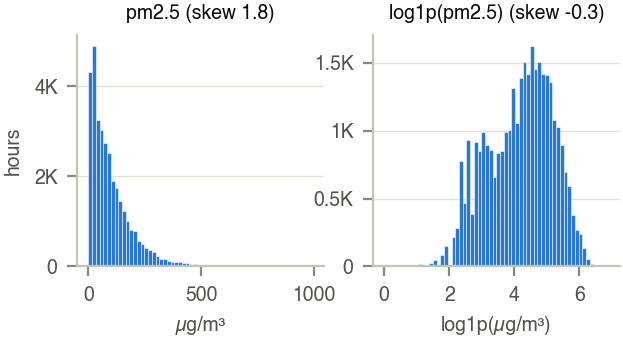

In [20]:
fig = viz.target_hist(df[dev])

**Takeaway.** PM2.5 and the wind columns have skew well above 1: a long right tail where a few huge values would
dominate a squared-error loss. log1p brings PM2.5 from 1.81 to -0.29. The snow and rain counters stay skewed because
they are almost always 0; the flags from A5 are the useful form.

## A8. Summary: preprocessing decisions

| Finding | Preprocessing decision | Step in `02_data_preprocessing` |
|---|---|---|
| Complete hourly grid, no duplicates | Validate the grid and fail loudly if it breaks; no resampling | 1 |
| Only PM2.5 is missing; weather is complete | Validate that weather stays complete; fill nothing in the weather | 1 |
| `Iws` is a running total per direction run | Decode to hourly wind speed `ws`; keep the total as `ws_cum` | 2 |
| `Is`, `Ir` are counters, mostly 0 | Snow and rain flags (counter > 0); keep the counters | 3 |
| Four wind directions, no SW | One-hot in the fixed order NE, NW, SE, cv | 4 |
| Missing labels can never be known | Leave the label `pm25` untouched; those hours are skipped in training and scoring | 5 |
| Gaps are mostly short; filling costs 13 at 1 h and 27 at 3 h, 41 at 6 h | Input copy `pm25_in` carried forward for at most 3 hours; longer gaps stay missing | 5 |
| Interpolation would use the future | No interpolation | 5 |
| Missingness is concentrated in 2010 to 2012 | Missing flag `pm25_miss` so models can tell a filled value from a real one | 5 |
| Extremes are real Lunar New Year and episode values | Keep them; no clipping | none |
| PM2.5 and wind columns are heavily skewed | log1p for those columns before scaling | 6 |

# Part B - Exploration (2010 to 2013)

From here on, only the development years are used. Helper columns for analysis: hourly wind speed from A5,
relative humidity from temperature and dew point, and snow and rain flags.

In [21]:
dv = df.assign(ws=ws, rh=rel_humidity(df["temp"], df["dewp"]),
               rain=(df["rain_cum"] > 0).astype("int8"), snow=(df["snow_cum"] > 0).astype("int8"))
dv = dv[dv.index.year < TEST]
pm = dv["pm25"]
print(dv.shape, dv.index.min(), "->", dv.index.max(), "| test year hidden:", TEST)

(35064, 12) 2010-01-01 00:00:00 -> 2013-12-31 23:00:00 | test year hidden: 2014


## B1. The series at a glance

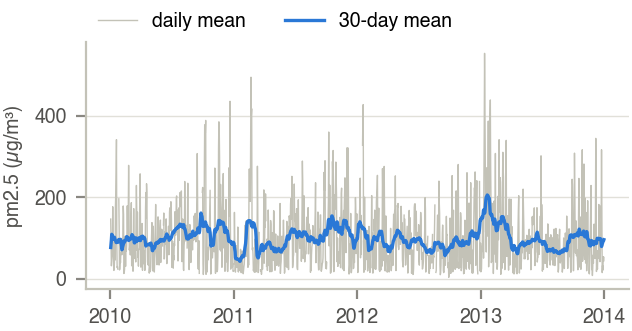

In [22]:
fig = viz.daily_series(dv)

In [23]:
pm.groupby(dv.index.year).agg(mean="mean", median="median", p90=lambda s: s.quantile(0.9),
                              max="max", missing=lambda s: s.isna().sum())

,mean,median,p90,max,missing
ts,,,,,
2010,104.05,79.0,225.0,980.0,669
2011,99.07,71.0,232.0,595.0,728
2012,90.55,69.0,197.0,994.0,489
2013,101.71,71.5,231.0,886.0,82


**Takeaway.** No trend across the four years (yearly mean 90.5 to 104.0). The variation is inside each year:
daily means swing from clean days to several hundred within a week, and every winter has its own bursts.

## B2. How often is the air polluted?

Hours per category of China's air quality standard (HJ 633-2012). The standard uses 24-hour averages, so applying
its PM2.5 breakpoints to single hours is an approximation for context only. HJ 633-2012 was replaced by HJ 633-2026 on
2026-03-01, which revises the PM2.5 limits; the 2012 breakpoints are used here because they match the data period.

In [24]:
labels = ["excellent (0-35)", "good (35-75)", "lightly polluted (75-115)", "moderately polluted (115-150)",
          "heavily polluted (150-250)", "severely polluted (>250)"]
cat = pd.cut(pm, [0, 35, 75, 115, 150, 250, np.inf], labels=labels, include_lowest=True)
cat.value_counts(normalize=True).reindex(labels).mul(100).rename("% of observed hours").to_frame()

,% of observed hours
pm25,
excellent (0-35),28.96
good (35-75),22.44
lightly polluted (75-115),16.78
moderately polluted (115-150),9.90
heavily polluted (150-250),14.71
severely polluted (>250),7.21


**Takeaway.** About half of all hours (51.4%) are good or excellent, but 21.9% are heavily or severely polluted
(above 150). That 150 line is the threshold used for episodes in B7.

## B3. Cycles

Median PM2.5 by hour of day for winter and summer, mean and median by month, and by day of week.

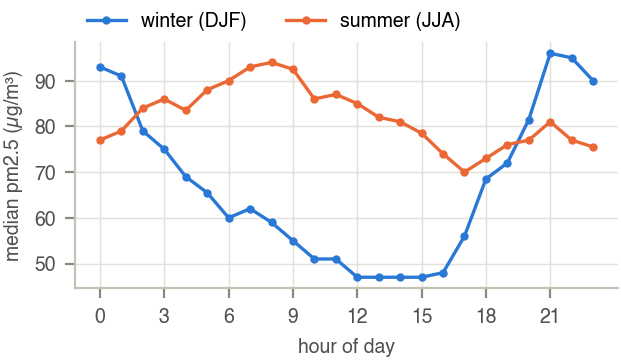

In [25]:
fig = viz.diurnal_profile(dv)

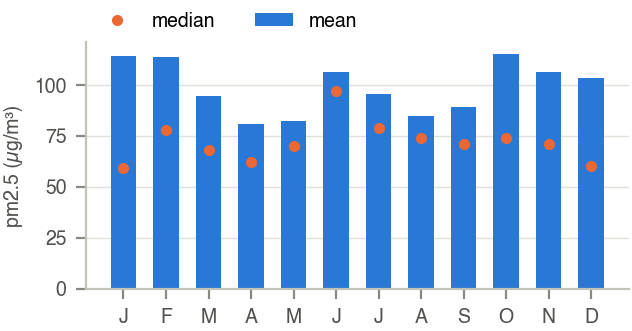

In [26]:
fig = viz.monthly_profile(dv)

In [27]:
dow = pm.groupby(dv.index.dayofweek).agg(["mean", "median"])
dow.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
dow.T

,Mon,Tue,Wed,Thu,Fri,Sat,Sun
mean,96.16,99.49,98.2,93.48,99.51,103.15,101.97
median,73.00,75.00,67.0,69.00,74.00,78.00,73.00


**Takeaway.**
- Winter and summer have opposite daily shapes. Winter peaks at 21:00 (median 96) and is lowest from 12:00 to
  15:00 (47). Summer peaks at 08:00 (94) and is lowest at 17:00 (70).
  So hour of day only makes sense together with the season.
- In January and December the mean is almost twice the median (114 vs 59 and 103 vs 60): winter mixes very
  clean days with severe episodes, a heavy tail.
- Day of week barely matters (mean 93.5 to 103.2).

## B4. Memory: how long does PM2.5 remember its past?

- ACF: correlation between log1p(PM2.5) now and k hours ago.
- PACF: the same after removing what the shorter lags already explain, so it shows which lags add new information.
  It needs a gap-free series, so missing hours are carried forward for this one calculation only.
- Error of copying the past at several horizons, on hours where both values were observed. The grey band in the
  chart is the 95% range for pure noise.

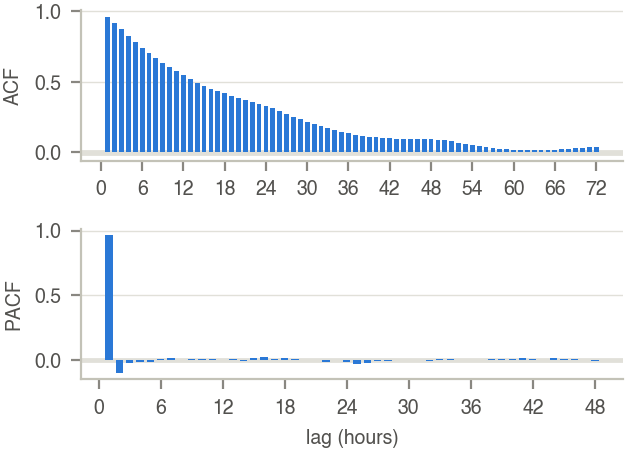

In [28]:
z = np.log1p(pm)
acf = pd.Series({k: z.autocorr(k) for k in range(1, 73)})
zf = z.ffill().dropna()
pa = pd.Series(pacf(zf, nlags=48)[1:], index=range(1, 49))
fig = viz.acf_pacf(acf, pa, len(zf))

In [29]:
pd.DataFrame({"ACF": acf, "PACF": pa}).loc[[1, 2, 3, 4, 6, 12, 23, 24, 25, 48]].T

,1,2,3,4,6,12,23,24,25,48
ACF,0.96,0.92,0.87,0.83,7.42e-01,5.46e-01,3.46e-01,0.33,0.31,9.26e-02
PACF,0.96,-0.10,-0.02,-0.01,7.28e-03,-1.02e-03,1.01e-03,-0.02,-0.03,-7.31e-03


In [30]:
rows = []
for h in [1, 2, 3, 6, 12, 24]:
    y, seas = pm.shift(-h), pm.shift(24 - h)
    ok = y.notna() & pm.notna() & seas.notna()
    rows.append({"h": h, "persistence MAE": (y - pm)[ok].abs().mean(),
                 "seasonal-naive MAE": (y - seas)[ok].abs().mean(), "lag-h correlation": pm.autocorr(h)})
pd.DataFrame(rows).set_index("h")

,persistence MAE,seasonal-naive MAE,lag-h correlation
h,,,
1,13.11,69.81,0.96
2,20.83,69.87,0.92
3,27.02,69.90,0.87
6,40.81,69.86,0.74
12,56.37,69.84,0.55
24,69.78,69.78,0.39


**Takeaway.**
- Memory is long but fading: ACF 0.96 at 1 h, 0.74 at 6 h, 0.33 at 24 h.
- PACF says almost all direct information sits in the last hour, with a small correction at lag 2 (-0.10) and a
  faint daily echo at 24 to 25 h (-0.02, -0.03). Recent lags matter most; a few longer lags are cheap insurance.
- Copying the current value is wrong by about 13 at 1 h, 41 at 6 h and 70 at 24 h. The seasonal-naive is about 70
  at every horizon, so it only ties with persistence at 24 h.

## B5. Weather and PM2.5

PM2.5 by wind direction and by wind speed, then rank (Spearman) correlations of each weather variable with PM2.5
now and 6 hours later.

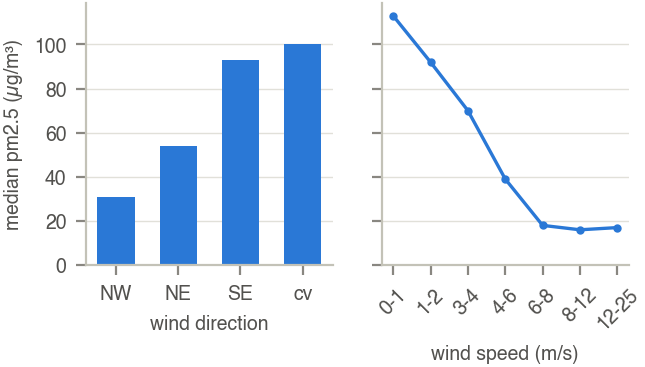

In [31]:
fig = viz.wind_effect(dv)

In [32]:
dv.groupby("cbwd").agg(hours=("pm25", "size"), mean_pm=("pm25", "mean"),
                       median_pm=("pm25", "median"), mean_ws=("ws", "mean"))

,hours,mean_pm,median_pm,mean_ws
cbwd,,,,
NE,3994,90.16,54.0,2.61
NW,11694,69.35,31.0,4.58
SE,12068,113.20,93.0,2.81
cv,7308,127.19,100.0,0.99


In [33]:
wx = dv[["dewp", "temp", "pres", "rh", "ws", "ws_cum", "rain", "snow"]]
pd.DataFrame({"with pm25 at t": wx.corrwith(pm, method="spearman"),
              "with pm25 at t+6": wx.corrwith(pm.shift(-6), method="spearman")})

,with pm25 at t,with pm25 at t+6
dewp,3.29e-01,0.27
temp,4.41e-02,0.07
pres,-1.72e-01,-0.14
rh,5.36e-01,0.39
ws,-4.60e-01,-0.46
ws_cum,-3.76e-01,-0.34
rain,4.05e-03,-0.05
snow,4.75e-02,0.05


In [34]:
pm.groupby(pd.cut(dv["rh"], [0, 20, 40, 60, 80, 90, 100]), observed=True).agg(["size", "median"])

,size,median
rh,,
"(0, 20]",3423,21.0
"(20, 40]",8420,30.0
"(40, 60]",7051,79.0
"(60, 80]",7902,105.0
"(80, 90]",4929,118.0
"(90, 100]",3338,129.0


**Takeaway.**
- Calm (cv) and SE winds bring the dirtiest air (median 100 and 93), NW the cleanest (31).
- PM2.5 falls steadily as wind speed rises to about 6 m/s, then flattens.
- Relative humidity is the strongest single weather signal (Spearman 0.54 now, 0.39 six hours ahead), stronger than
  dew point (0.33). Median PM2.5 climbs from 21 in dry air to 129 above 90% humidity.
- Temperature, rain and snow on their own show almost no rank correlation.

## B6. What predicts the next 6 hours?

Change over the next 6 hours as a ratio: +50% means PM2.5 at t+6 is 1.5 times PM2.5 at t. Grouped by wind
direction now, by how long the current NW spell has lasted, and by the pressure change over the last 3 hours.

In [35]:
dlog = np.log1p(pm.shift(-6)) - np.log1p(pm)
dir_hours = dv.groupby(dv["cbwd"].ne(dv["cbwd"].shift()).cumsum()).cumcount() + 1


def next6(groups):
    g = dlog.groupby(groups, observed=True)
    return pd.DataFrame({"hours": g.count(), "median change %": 100 * np.expm1(g.median()),
                         "share halving %": 100 * g.apply(lambda s: (s.dropna() < np.log(0.5)).mean())})


next6(dv["cbwd"])

,hours,median change %,share halving %
cbwd,,,
NE,3713,3.12,14.09
NW,10931,-4.35,18.46
SE,11223,16.83,7.25
cv,6800,7.22,11.82


In [36]:
nw = dv["cbwd"].eq("NW")
next6(pd.cut(dir_hours[nw], [0, 3, 6, 12, 24, 1000], labels=["1-3", "4-6", "7-12", "13-24", ">24"]))

,hours,median change %,share halving %
1-3,4679,-12.22,24.02
4-6,1922,-9.49,22.16
7-12,1975,0.65,14.43
13-24,1451,10.00,9.99
>24,904,17.65,4.20


In [37]:
next6(pd.cut(dv["pres"].diff(3), [-np.inf, -1, 0, 1, 2, np.inf]))

,hours,median change %,share halving %
pres,,,
"(-inf, -1.0]",11148,17.76,8.26
"(-1.0, 0.0]",9552,4.72,11.88
"(0.0, 1.0]",7624,0.13,15.37
"(1.0, 2.0]",3031,-1.22,19.53
"(2.0, inf]",1312,-21.43,25.84


**Takeaway.**
- SE wind now means PM2.5 tends to rise (median +17% in 6 h). NW wind means it tends to fall (-4%, with an 18%
  chance of halving).
- The first 3 hours of a NW spell are the strongest clearing signal (-12%, 24% chance of halving). NW spells older
  than 24 h see PM2.5 rising again (+18%). So how long the wind has blown matters, not just its direction.
- Pressure rising by more than 2 hPa in 3 h, typical of a cold front, gives -21% and a 26% chance of halving.
  Falling pressure gives +18%.

## B7. Pollution episodes

An episode here means PM2.5 above 150 for at least 6 consecutive hours (a working definition, not an official
one). For each episode: how long it lasted, how many hours it took to build from the lowest point of the previous
72 hours to the peak, how many hours it took to fall below a quarter of the peak, and the wind at that moment.

In [38]:
hi = pm > 150
ep_id = (hi != hi.shift()).cumsum()
rows = []
for _, e in dv[hi].groupby(ep_id[hi]):
    if len(e) < 6:
        continue
    peak_t = e["pm25"].idxmax()
    before = pm.loc[:peak_t].iloc[-73:-1]
    after = dv.loc[peak_t:].iloc[1:73]
    clear = after[after["pm25"] < 0.25 * e["pm25"].max()]
    rows.append({"start": e.index[0], "hours": len(e), "peak": e["pm25"].max(),
                 "build_h": (peak_t - before.idxmin()).total_seconds() / 3600 if before.notna().any() else np.nan,
                 "clear_h": (clear.index[0] - peak_t).total_seconds() / 3600 if len(clear) else np.nan,
                 "clear_wind": clear["cbwd"].iloc[0] if len(clear) else None})
episodes = pd.DataFrame(rows)
pd.Series({"episodes": len(episodes), "median duration (h)": episodes["hours"].median(),
           "longest (h)": episodes["hours"].max(), "median build-up (h)": episodes["build_h"].median(),
           "median clearing (h)": episodes["clear_h"].median(),
           "hours in episodes (%)": 100 * episodes["hours"].sum() / pm.notna().sum()}).round(1).to_frame("value")

,value
episodes,322.0
median duration (h),14.0
longest (h),111.0
median build-up (h),55.0
median clearing (h),14.0
hours in episodes (%),19.0


In [39]:
pd.DataFrame({"at clearing (%)": episodes["clear_wind"].value_counts(normalize=True).mul(100),
              "all hours (%)": dv["cbwd"].value_counts(normalize=True).mul(100)}).round(1)

,at clearing (%),all hours (%)
NE,17.3,11.4
NW,54.9,33.4
SE,19.1,34.4
cv,8.7,20.8


Two episodes in December 2010. Shaded hours have NW wind.

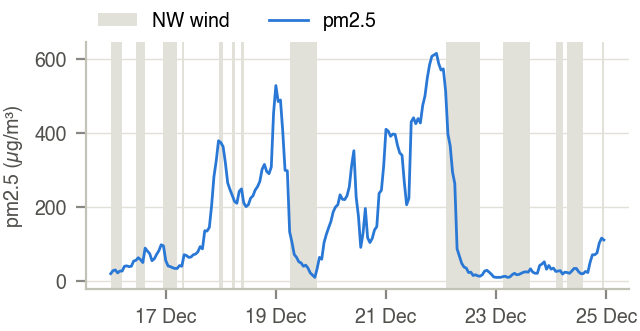

In [40]:
fig = viz.episode_example(dv, "2010-12-16", "2010-12-24")

**Takeaway.**
- 322 episodes cover 19% of observed hours.
- They build slowly (median 55 h from the previous low to the peak) and clear fast (median 14 h to fall below a
  quarter of the peak). The 55 h is approximate because the look-back window is capped at 72 h.
- NW wind is blowing at 55% of clearings, against 33% of all hours.
- The December 2010 example shows the saw-tooth: a slow build under SE and calm air, then a collapse within
  hours when the NW wind arrives.
- Episode hours are where large errors will come from, so the models are also scored on them separately.

## B8. Lunar New Year

Fireworks on the eve and first day of Lunar New Year. The table compares the peak on those two days with the
median of the surrounding two weeks.

In [41]:
rows = []
for day in LNY[LNY.year < TEST]:
    days = dv.loc[day - pd.Timedelta(days=1): day + pd.Timedelta(hours=23), "pm25"]
    around = dv.loc[day - pd.Timedelta(days=8): day + pd.Timedelta(days=8), "pm25"].drop(days.index)
    rows.append({"date": day.date(), "peak on eve and day": days.max(), "peak hour": days.idxmax(),
                 "median of surrounding 2 weeks": around.median()})
pd.DataFrame(rows).set_index("date")

,peak on eve and day,peak hour,median of surrounding 2 weeks
date,,,
2010-02-14,980.0,2010-02-14 01:00:00,68.0
2011-02-03,348.0,2011-02-03 01:00:00,42.0
2012-01-23,994.0,2012-01-23 01:00:00,76.0
2013-02-10,512.0,2013-02-09 22:00:00,70.5


**Takeaway.** Every year the peak on the eve or first day is 7 to 14 times the usual level (980 vs 68 in 2010,
994 vs 76 in 2012), always between 22:00 and 01:00. No weather variable explains this, so a calendar flag is the
only way a model can expect it.

## B9. Are the weather inputs redundant?

Pearson correlations among weather variables. Strong pairs carry overlapping information.

In [42]:
wx[["dewp", "temp", "pres", "rh", "ws"]].corr()

,dewp,temp,pres,rh,ws
dewp,1.00,0.83,-0.78,0.62,-0.34
temp,0.83,1.00,-0.82,0.10,-0.04
pres,-0.78,-0.82,1.00,-0.26,0.10
rh,0.62,0.10,-0.26,1.00,-0.53
ws,-0.34,-0.04,0.10,-0.53,1.00


**Takeaway.** Dew point, temperature and pressure move together (absolute r 0.78 to 0.83). Trees are not hurt by
this, but a linear model's coefficients become unstable, so Ridge needs its regularisation.

## B10. Stationarity

Augmented Dickey-Fuller test on daily mean log1p(PM2.5). A small p-value rejects a unit root, meaning the series
keeps returning to its typical level instead of drifting away.

In [43]:
daily = np.log1p(pm.resample("D").mean()).dropna()
stat, p, lags, nobs, *_ = adfuller(daily, autolag="AIC")
pd.Series({"ADF statistic": stat, "p-value": p, "lags used": lags, "days": nobs}).to_frame("value")

,value
ADF statistic,-22.21
p-value,0.00
lags used,1.00
days,1422.00


**Takeaway.** ADF statistic -22.2 with p < 0.001: the series is stationary around a stable level. Models can
work on log1p levels with lags; no differencing is needed.

## B11. Summary: modelling decisions

| Finding | Decision in Phase 1 | Where in `03_phase1_models` |
|---|---|---|
| Strong short memory; PACF mostly at lag 1, small at 2 and at 24 to 25 h | lags 1, 2, 3, plus 6, 12, 24, 48 for the longer horizons; rolling mean, std, max | features: lags, rolling |
| Copying is good at 1 h (MAE about 13) and poor at 24 h (about 70) | headline horizon 6 h; persistence and seasonal-naive as baselines | steps 3 and 7 |
| Opposite daily shapes in winter and summer | hour and month of the target hour as sin / cos; trees learn the interaction | features: calendar |
| Day of week is weak | keep day of week and weekend, expect low importance | features: calendar, step 9 |
| Wind direction and speed separate PM2.5 levels sharply | wind one-hot, hourly and cumulative wind speed | features: weather |
| Relative humidity is the strongest weather signal | derived relative humidity | features: derived |
| Fresh NW spells and rising pressure predict drops | hours since the wind changed, NW wind run over 24 h, pressure change over 3 and 24 h | features: derived |
| Episodes: 19% of hours, slow build, fast clearing | separate score on episode hours | step 10 |
| Winter mean about twice the median (heavy tail) | log1p target; check bias and Duan smearing | step 8 |
| Lunar New Year peaks 7 to 14 times normal | Lunar New Year flag | features: calendar |
| Dew point, temperature, pressure strongly correlated | Ridge with alpha chosen on validation folds | step 4 |
| Series is stationary | model log1p levels with lags, no differencing | all models |